# 🐍 Python Foundations for AI
## Class 9 — AI Libraries & APIs

**Alexandra Oliveira** · AI Engineer  
**Catarina Santos** · AI Engineer

---

<div style="display:flex; align-items:center; gap:24px; margin-bottom:8px;">
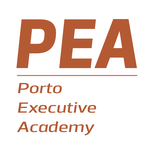
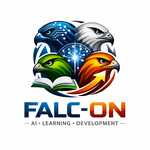
</div>

---

### 📋 What we'll cover today

| # | Topic |
|---|-------|
| 1 | What is a module? |
| 2 | The standard library — batteries included |
| 3 | Installing more with `pip` — and reproducibility |
| 4 | Your own module: `falcon_tools` |
| 5 | The three ways to import |
| 6 | Packages — when one file is not enough |
| 7 | What is an API? |
| 8 | Real-time data from a web API |
| 9 | LLMs, providers, and API keys |
| 10 | Calling Gemini from Python |
| 11 | 🔗 Capstone — FALC-ON AI gets a real brain |

### 🎯 Learning outcomes

By the end of this class you will be able to:

- Use the standard library, install a library, and keep a project reproducible
- Move your own code into a module, and import it
- Fetch real-time data from a web API, and process it
- Call an AI model from your own code — safely, with your key kept secret

### 🤖 AI ≠ just prompting

A real AI application is a **program**: it is built from libraries, it keeps its own code in modules, it pulls in **live data** from the web, and it sends prompts to an **AI model** through an API.

Since Class 1, FALC-ON AI has answered with a **stand-in model** — a dictionary and a keyword search. Today it gets a real one.

---
## 1. What Is a Module?

A **module** is a file with things in it — functions, classes, values — that another file can borrow. You have used them since Class 3:

```
import pandas as pd
```

`pandas` is a module (a very large one). `import` finds it and makes its contents available under the name `pd`.

| | One long notebook | Split into modules |
|---|------------------|--------------------|
| Finding a function | scroll | it is in the file named after its job |
| Using it in another notebook | copy and paste | `import` it |
| Fixing a bug | fix every copy | fix it once |
| Two people working | one notebook, one person | a file each |

The rule is the one from Class 4, one level up: **give the job a name.** There it was a function; here it is a file.

---
## 2. The Standard Library — Batteries Included

Python comes with hundreds of modules already installed. Nothing to download; just `import`.

| Module | For | Examples |
|--------|-----|----------|
| `math` | maths beyond `+ - * /` | `math.sqrt()`, `math.ceil()` |
| `random` | random choices | `random.choice()`, `random.randint()`, `random.seed()` |
| `statistics` | averages | `statistics.mean()`, `statistics.median()` |
| `datetime` | dates | `date.today()`, `.strftime()` |

> 💡 Before writing a function, spend thirty seconds checking whether Python already has it.

Two of them, in action:

### `random` — and why AI people fix the seed

`random.seed()` makes the "random" results come out **the same on every run**. It sounds like a contradiction, but it is exactly what an AI experiment needs: someone else can repeat it, and get your results.

In [ ]:
import random

random.seed(42)                        # the same "random" results on every run
print(random.choice(["Ana", "Bruno", "Carla", "Dora"]))
print(random.randint(1, 5))            # a whole number from 1 to 5

### `statistics` — averages without writing them

In [ ]:
import statistics

ratings = [5, 2, 4, 1, 3, 5]

print(statistics.mean(ratings))        # 3.3333333333333335
print(statistics.median(ratings))      # 3.5 - the middle value

---
## 3. Installing More with `pip` — and Reproducibility

Everything else lives on **PyPI**, the Python Package Index — over half a million free libraries. `pip` fetches one and puts it where `import` can find it:

```
!pip install -q import-ipynb
```

| Piece | Means |
|-------|-------|
| `!` | *"this is not Python, it is a command for the computer"* |
| `-q` | quiet: hides pages of output you will not read |

> ⚠️ In Colab, an install lasts only for the **current session**. The `!pip install` line stays at the top of the notebook, and runs again each time. That is normal — not a mistake.

In [ ]:
!pip install -q import-ipynb

### Reproducibility — the same versions, the same results

Libraries change. A different version of pandas can give a different result, or an error — and in AI, a different version of a model library can give different answers. So a project lists the **exact versions** it uses, in a file called `requirements.txt`:

```
pandas==2.2.3
matplotlib==3.10.0
seaborn==0.13.2
```

Anyone can then recreate the same set-up with `pip install -r requirements.txt`. To see which version you have:

In [ ]:
import pandas as pd

print(pd.__version__)                  # the version installed here

---
## 4. Your Own Module: `falcon_tools`

A module of your own is just **your own code, kept somewhere else**. In Colab, that somewhere else is another **notebook**.

Open **`falcon_tools.ipynb`**. It holds everything FALC-ON AI is made of so far — only **definitions**, plus a small self-test at the bottom.

| Name | What it is | From |
|------|-----------|------|
| `KNOWLEDGE`, `UNKNOWN` | the knowledge dictionary, and the "don't know" reply | Class 2 |
| `clean_text()`, `find_answer()` | the helper, and the stand-in model | Class 4 |
| `ChatMemory` | the long-term memory in SQLite | Classes 7 and 8 |
| `FalconAssistant` | the assistant that answers and remembers | Class 8 |

> 📁 **`falcon_tools.ipynb` must sit next to this notebook.** In Colab, open the **Files** panel (📁 in the left sidebar) and upload it. If Python says `No module named 'falcon_tools'`, this is why.

### A module that stays quiet — `if __name__ == "__main__":`

A module is meant to be **imported**, so it should not print anything when it is. But while you write it, you want to **test** it. The bottom of `falcon_tools.ipynb` does both, with one line:

```
if __name__ == "__main__":
    print("Running falcon_tools directly - self-test:")
    ...
```

`__name__` — two underscores on each side — is a variable Python creates for you in every notebook and module:

| Where the code runs | `__name__` holds |
|---------------------|------------------|
| the notebook you run yourself | `"__main__"` |
| a notebook brought in with `import` | its own name: `"falcon_tools"` |

So the `if` is `True` only when you run `falcon_tools.ipynb` yourself: the self-test runs then — and stays silent when another notebook imports it.

In [ ]:
print(__name__)                        # __main__ - this is the notebook we are running

### Importing it

Python needs the helper **`import_ipynb`** — installed in Section 3 — to import a notebook.

In [ ]:
import import_ipynb                    # lets Python import .ipynb notebooks
import falcon_tools                    # runs falcon_tools.ipynb, and hands us what it defines

In [ ]:
print(falcon_tools.clean_text("  What is COLAB?  "))
print(falcon_tools.find_answer("how many classes?"))
print(falcon_tools.UNKNOWN)            # values come across too, not just functions

**The self-test did not print.** Inside the imported module, `__name__` is `"falcon_tools"`, not `"__main__"` — so the `if` was `False`, and the self-test was skipped:

In [ ]:
print(falcon_tools.__name__)           # falcon_tools - the module's own name

> ⚠️ **Change the module, and Python may ignore you.** Once a module is imported, Python remembers it and does not read the file again. If an edit seems to have no effect: *Runtime → Restart session*, then run this notebook from the top. This catches everybody once.

---
## 5. The Three Ways to Import

| Written | You then type | Use it when |
|---------|---------------|-------------|
| `import falcon_tools` | `falcon_tools.find_answer(q)` | the default — it is obvious where the function came from |
| `from falcon_tools import find_answer` | `find_answer(q)` | you want one or two things, a lot |
| `import falcon_tools as ft` | `ft.find_answer(q)` | the name is long, or convention says so |

The third is why everyone writes `import pandas as pd`.

In [ ]:
from falcon_tools import clean_text, find_answer

print(find_answer(clean_text("How many CLASSES are there?")))

In [ ]:
import falcon_tools as ft

print(ft.KNOWLEDGE["teach"])

### Why not `from falcon_tools import *`

It exists, it imports everything — and you should not use it:

- You cannot tell where a name came from. Reading `clean_text(q)`, is that yours? A library's?
- If two modules both define `clean_text`, the second silently wins
- Names you did not want land in your notebook too

---
## 6. Packages — When One File Is Not Enough

A **package** is a folder of modules. Big libraries like pandas are organised this way:

```
   falcon_ai/
   ├── __init__.py       marks the folder as a package - often empty
   ├── tools.py          falcon_ai.tools
   └── memory.py         falcon_ai.memory
```

Then `from falcon_ai.tools import clean_text` reaches into the folder with a dot — the `from … import` of Section 5, one level deeper.

> 💡 **You do not need to build one today.** This is here so the structure is not a mystery when you open a project and find folders of `.py` files, each with an empty `__init__.py`. That is all it is.

---
## 7. What Is an API?

An **API** (Application Programming Interface) is a way for **one program to talk to another** — usually over the web.

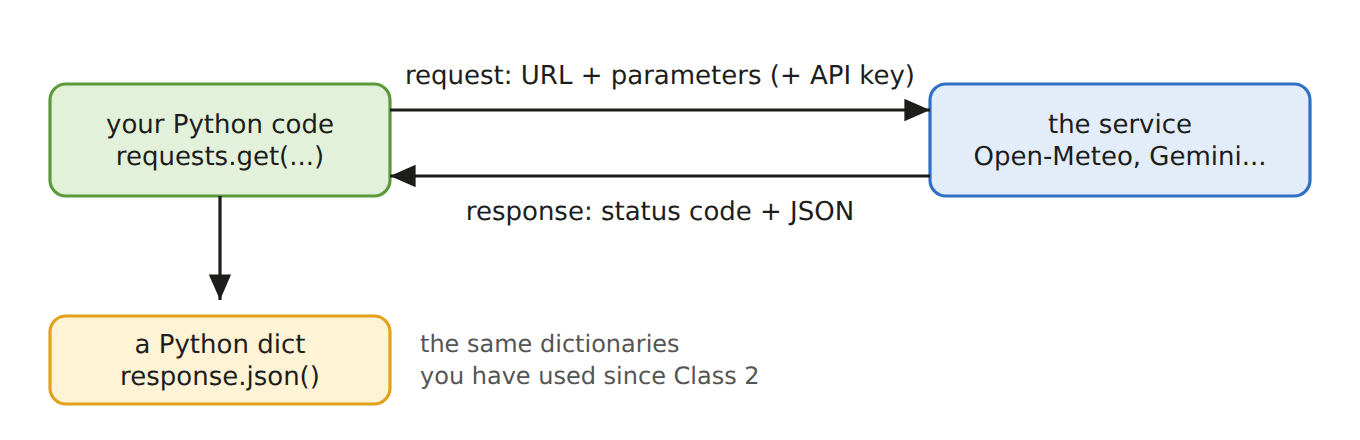

| Piece | What it is |
|-------|-----------|
| **URL** | the address of the service |
| **Parameters** | what you are asking for — a dictionary |
| **API key** | a secret password that says who you are (not every API needs one) |
| **Status code** | a number saying how it went: `200` OK, `401`/`403` a problem with your key, `404` wrong address, `429` too many requests — wait and try again |
| **JSON** | the answer — which becomes a Python dictionary |

It works the same whether you talk to a weather service or to an AI model.

---
## 8. Real-Time Data from a Web API

**Open-Meteo** gives live weather data, for free, with **no key**. The `requests` library sends the request; it is already installed in Colab.

In [ ]:
import requests

URL = "https://api.open-meteo.com/v1/forecast"
params = {"latitude": 41.15, "longitude": -8.61, "current": "temperature_2m"}   # Porto

response = requests.get(URL, params=params)
print(response.status_code)            # 200 means OK

In [ ]:
data = response.json()                 # the JSON answer, as a dictionary
print(data["current"])

In [ ]:
temperature = data["current"]["temperature_2m"]
print("Porto right now:", temperature, "°C")

### Always check the status code

A request can fail — no internet, a wrong address, too many requests. Check the status code **before** you use the answer:

In [ ]:
response = requests.get(URL, params=params)

if response.status_code == 200:
    print("Porto right now:", response.json()["current"]["temperature_2m"], "°C")
else:
    print("The request failed, with status", response.status_code)

### Fetch *and* process

One request per city, the answers collected in a dictionary — then processed with Class 5's `max()` and a `key`.

In [ ]:
cities = [
    {"name": "Porto",  "latitude": 41.15, "longitude": -8.61},
    {"name": "Lisbon", "latitude": 38.72, "longitude": -9.14},
    {"name": "London", "latitude": 51.51, "longitude": -0.13},
]

temperatures = {}
for city in cities:
    params = {"latitude": city["latitude"], "longitude": city["longitude"], "current": "temperature_2m"}
    data = requests.get(URL, params=params).json()
    temperatures[city["name"]] = data["current"]["temperature_2m"]

print(temperatures)

In [ ]:
warmest = max(temperatures, key=lambda name: temperatures[name])
print("Warmest right now:", warmest)

> 💡 **This is real-time data.** Run the cells again in an hour, and the numbers will have changed.

---
## 9. LLMs, Providers, and API Keys

A **Large Language Model (LLM)** is an AI model trained on enormous amounts of text. Given a text — the **prompt** — it generates a text **response**. LLMs power assistants like Gemini, ChatGPT and Claude.

You reach an LLM through its provider's **API**. The idea is always the same — *send a prompt, get text back* — but **each provider has its own library and syntax**:

| Provider | Library | The call |
|----------|---------|----------|
| Google — Gemini | `google-genai` | `client.models.generate_content(model=MODEL, contents=prompt)` |
| OpenAI — GPT | `openai` | `client.chat.completions.create(model=MODEL, messages=[...])` |
| Anthropic — Claude | `anthropic` | `client.messages.create(model=MODEL, max_tokens=500, messages=[...])` |

> 💡 See `messages=[...]`? It is the **list of message dictionaries** from Class 2 — `{"role": "user", "content": "..."}`. You already know the shape real assistants use.

> 💡 Model names change every few months. Keep the name in **one** variable, `MODEL`, so you change it in one place. Today we use **Gemini**, with a key the course gives you.

### Your API key — a password, kept secret

An **API key** is a password that says who you are — and who pays. Anyone who has it can use the account, and the bill comes to its owner.

For this course, **we give you the key**: the course pays for it, and the whole class shares it. So these rules matter:

- 🔑 It goes **only** in Colab's **Secrets** panel — never in a notebook, a screenshot, a chat or GitHub, and never forward it. Notebooks get shared, and a key in one is a key given away.
- 💶 Use it **only for the course work**: every request costs money.
- 🚨 **Shared it by mistake?** Tell us straight away: we cancel it and send everyone a new one.
- 📅 It works until the project deadline, **21 November**; after that we switch it off.

### 🔑 Where your key comes from

You **do not** create a key: you receive the course key from us, in a private message. It is a long code that starts with `AIza`. Keep that message — you paste the key into Colab in the next step, **once**.

### 🔑 Step by step — save the key in Colab

1. In your Colab notebook, click the **🔑 key icon** in the left sidebar, just above the 📁 folder icon — the **Secrets** panel.
2. Click **+ Add new secret**.
3. In **Name**, type `GEMINI_API_KEY` — exactly like this, in capital letters: the code in this course always looks for this name.
4. In **Value**, paste the key you received from us.
5. Switch on **Notebook access**, so this notebook may read it.

Your key is now saved in **your** Google account, not in the notebook: if you share the notebook, the key does not go with it. In the next section, one line reads it: `userdata.get("GEMINI_API_KEY")`.

> 💡 In another notebook — your final project, for example — the secret is already there: just switch on **Notebook access** for that notebook too.

---
## 10. Calling Gemini from Python

Three steps: install the library, create a **client** with your key, and send a prompt.

In [ ]:
!pip install -q google-genai

In [ ]:
from google.colab import userdata
from google import genai

GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")    # read from the 🔑 Secrets panel
MODEL = "gemini-3.8-flash"                         # model names change: check ai.google.dev

# think only a little: faster answers; higher temperature = creative responses
FAST = {"thinking_config": {"thinking_level": "low"}, "temperature": 1.5}

client = genai.Client(api_key=GEMINI_API_KEY)

Newer models **think** before they answer, and thinking takes time. `FAST` asks Gemini to think only a little — plenty for our questions, and much quicker.

A function hides the details, so the rest of the program simply calls `ask_gemini(prompt)`:

In [ ]:
def ask_gemini(prompt):
    """Send a prompt to Gemini, and return its text answer."""
    response = client.models.generate_content(model=MODEL, contents=prompt, config=FAST)
    return response.text

In [ ]:
print(ask_gemini("Explain what an API is, in one sentence."))

### Ask twice, get two answers

An LLM does not look its answer up — it **generates** it, so the same prompt can give different answers. This is the variability you met in Class 6.

In [ ]:
for attempt in range(2):
    print(ask_gemini("Suggest a name for a friendly robot. Reply with the name only. Be creative"))

### When it goes wrong

| The error mentions | What happened | What to do |
|--------------------|---------------|-----------|
| `SecretNotFoundError` | no secret with that name | check the name in 🔑 is exactly `GEMINI_API_KEY` |
| `NotebookAccessError` | this notebook may not read the secret | switch on **Notebook access** for the secret in 🔑 |
| `API key not valid` / `400` / `403` | the key is wrong | copy the key again from the message we sent you |
| `429` / `RESOURCE_EXHAUSTED` | too many requests at once — the whole class shares one key | wait a minute, then run the cell again |
| `503` / `UNAVAILABLE` / `high demand` | Google's servers are busy — not your fault | wait a minute or two, then run the cell again |
| `404` / model `not found` / `no longer available` | that model has been retired | change `MODEL` to the model the error message suggests |

---
## 11. 🔗 Capstone — FALC-ON AI Gets a Real Brain

In Class 8, FALC-ON AI became two cooperating objects, and you were promised: *swap one part, and nothing else changes.* Today we keep that promise. Only `answer()` changes — from a keyword search to Gemini. The memory, the ratings, `chat_turn()` — all imported from `falcon_tools`, untouched.

### Step 1 — A grounded prompt

LLMs need context to be useful (Class 3). And an LLM that does not know something may **invent** an answer — a hallucination (Class 6). So the prompt gives the model **the facts**, and tells it what to say when the facts do not answer.

In [ ]:
def make_prompt(question, knowledge):
    """A prompt that answers only from the knowledge dictionary."""
    facts = list(knowledge.values())
    return f"""You are FALC-ON AI, the assistant of the course Python Foundations for AI.
Answer in one short sentence, using only these facts: {facts}
If the facts do not answer the question, reply exactly: {ft.UNKNOWN}
Question: {question}"""

In [ ]:
print(make_prompt("is colab free?", ft.KNOWLEDGE))

### Step 2 — Override one method

The Class 8 inheritance: `GeminiAssistant` **is a** `FalconAssistant` — it inherits `chat_turn()` and the memory, and only `answer()` is its own.

In [ ]:
from falcon_tools import FalconAssistant, ChatMemory

class GeminiAssistant(FalconAssistant):
    """FALC-ON AI with a real model: only answer() changes."""

    def answer(self, question):
        """Ask Gemini, grounded in this assistant's knowledge."""
        prompt = make_prompt(question, self.knowledge)
        return ask_gemini(prompt).strip()

### Step 3 — The stand-in against the real model

The stand-in only understands its keywords. The real model understands the question.

In [ ]:
memory = ChatMemory("memory.db")
stand_in = FalconAssistant("stand-in", ft.KNOWLEDGE, memory)
falcon = GeminiAssistant("FALC-ON AI", ft.KNOWLEDGE, memory)

question = "who are the instructors?"
print("Stand-in:", stand_in.answer(question))
print("Gemini:  ", falcon.answer(question))

### Step 4 — Chat, remember, learn

`chat_turn()` is inherited, so every turn goes into the memory as before — with its rating.

In [ ]:
print(falcon.chat_turn("ana", "Can I use Colab without paying?", 5))
print(falcon.chat_turn("ana", "How long is the course?", 4))
print(falcon.chat_turn("bruno", "When is the exam?", 2))

In [ ]:
for user, question, answer in memory.low_rated():
    print(f"{user}: {question} -> {answer}")

memory.close()

> 💡 Look at what **did not** change: `ChatMemory`, `chat_turn()`, the SQL, the ratings. One method swapped a keyword search for a real AI model. That is the whole point of modules, classes and encapsulation — and it is how you will build your final project.

---

### 🎉 That's Class 9!

| Concept | Key syntax |
|---------|------------|
| Standard library | ready to import: `random`, `statistics`, `math`, `datetime`… |
| Repeatable randomness | `random.seed(42)` |
| Install a library | `!pip install -q name` |
| Check a version | `pd.__version__`, pinned in `requirements.txt` |
| Import a notebook | `!pip install -q import-ipynb`, then `import import_ipynb` |
| Keep a module quiet | its self-test inside `if __name__ == "__main__":` |
| Three ways to import | `import x`, `from x import y`, `import x as y` — never `import *` |
| A package | a folder of modules with an `__init__.py` |
| Call a web API | `requests.get(URL, params=params)` |
| Check it worked | `response.status_code == 200` |
| Read the answer | `response.json()` — a dictionary |
| Keep a key secret | 🔑 Secrets, then `userdata.get("GEMINI_API_KEY")` |
| Call Gemini | `client.models.generate_content(model=MODEL, contents=prompt)`, then `.text` |

> ⚠️ **The three that will catch you:** the module notebook is not in the same folder; an edited module is ignored until you restart the session; a key pasted into a notebook that you then share.

> 🤖 **The big picture:** FALC-ON AI now has a real model, grounded in its own knowledge, with a long-term memory and user feedback — built from modules and classes, and talking to the world through APIs.

➡️ Now open the **exercises notebook**.